In [1]:
import torch
import pandas as pd
import numpy as np

from pathlib import Path
from transformers import AutoModelForSequenceClassification, AutoTokenizer

checkpoint_path = "../models/length_resource_experiment_256/checkpoint-339"
final_path = "../models/financesentinel_final"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = AutoModelForSequenceClassification.from_pretrained(checkpoint_path)
tokenizer = AutoTokenizer.from_pretrained(checkpoint_path)

model.to(device)
model.eval()

/home/pasali/anaconda3/envs/myenv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 104/104 [00:00<00:00, 8045.29it/s]


DistilBertForSequenceClassification(
  (distilbert): DistilBertModel(
    (embeddings): Embeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (transformer): Transformer(
      (layer): ModuleList(
        (0-5): 6 x TransformerBlock(
          (attention): DistilBertSelfAttention(
            (q_lin): Linear(in_features=768, out_features=768, bias=True)
            (k_lin): Linear(in_features=768, out_features=768, bias=True)
            (v_lin): Linear(in_features=768, out_features=768, bias=True)
            (out_lin): Linear(in_features=768, out_features=768, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
          (ffn): FFN(
            (dropout): Dropout(

In [2]:
model.save_pretrained(final_path, safe_serialization=True)
tokenizer.save_pretrained(final_path)

Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  2.30it/s]


('../models/financesentinel_final/tokenizer_config.json',
 '../models/financesentinel_final/tokenizer.json')

In [3]:
for file in Path(final_path).iterdir():
    print(f"{file.name}: {file.stat().st_size / 1e6:.4f} MB")

config.json: 0.0008 MB
tokenizer.json: 0.7115 MB
model.safetensors: 267.8356 MB
tokenizer_config.json: 0.0005 MB


In [4]:
parameter_count = sum(p.numel() for p in model.parameters())

weights_size = Path(final_path, "model.safetensors").stat().st_size / 1e6

folder_size = sum(
    file.stat().st_size
    for file in Path(final_path).rglob("*")
    if file.is_file()
) / 1e6

model_info = pd.DataFrame({
    "Parameter Count": [parameter_count],
    "Weights Size (MB)": [weights_size],
    "Folder Size (MB)": [folder_size],
    "Dtype": [str(next(model.parameters()).dtype)],
    "Transformer Layers": [model.config.n_layers],
    "Hidden Size": [model.config.dim],
    "Label Mapping": [model.config.id2label]
})

model_info.T

,0
Parameter Count,66955779
Weights Size (MB),267.835644
Folder Size (MB),268.548396
Dtype,torch.float32
Transformer Layers,6
Hidden Size,768
Label Mapping,"{0: 'Negative', 1: 'Neutral', 2: 'Positive'}"


In [5]:
final_model = AutoModelForSequenceClassification.from_pretrained(final_path)

final_tokenizer = AutoTokenizer.from_pretrained(final_path)

final_model.to(device)
final_model.eval()

Loading weights: 100%|██████████| 104/104 [00:00<00:00, 6973.07it/s]


DistilBertForSequenceClassification(
  (distilbert): DistilBertModel(
    (embeddings): Embeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (transformer): Transformer(
      (layer): ModuleList(
        (0-5): 6 x TransformerBlock(
          (attention): DistilBertSelfAttention(
            (q_lin): Linear(in_features=768, out_features=768, bias=True)
            (k_lin): Linear(in_features=768, out_features=768, bias=True)
            (v_lin): Linear(in_features=768, out_features=768, bias=True)
            (out_lin): Linear(in_features=768, out_features=768, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
          (ffn): FFN(
            (dropout): Dropout(

In [15]:
from sklearn.model_selection import train_test_split

df = pd.read_csv("../data/financial_sentiment.csv")

df = df.drop_duplicates(subset=["sentence"]).reset_index(drop=True)

train_df, temp_df = train_test_split(
    df,
    test_size=0.2,
    stratify=df["label"],
    random_state=42
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.5,
    stratify=temp_df["label"],
    random_state=42
)

print(train_df.shape)
print(val_df.shape)
print(test_df.shape)

print(val_df.shape)

val_df.head()

sample_df = val_df.sample(n=20, random_state=42)

sentences = sample_df["sentence"].tolist()

print(len(sentences))

(1807, 2)
(226, 2)
(226, 2)
(226, 2)
20


In [16]:
def get_predictions(model, tokenizer, sentences):

    inputs = tokenizer(
        sentences,
        padding=True,
        truncation=True,
        max_length=256,
        return_tensors="pt"
    ).to(device)

    with torch.inference_mode():
        logits = model(**inputs).logits

        probabilities = torch.softmax(logits, dim=1)

        predicted_labels = probabilities.argmax(dim=1)

    return logits.cpu(), probabilities.cpu(), predicted_labels.cpu()

In [17]:
original_logits, original_probs, original_preds = get_predictions(
    model, tokenizer, sentences
)

final_logits, final_probs, final_preds = get_predictions(
    final_model, final_tokenizer, sentences
)


logits_equal = torch.allclose(
    original_logits, final_logits, atol=1e-6, rtol=1e-5
)

probabilities_equal = torch.allclose(
    original_probs, final_probs, atol=1e-6, rtol=1e-5
)

predictions_equal = torch.equal(
    original_preds, final_preds
)

print("Logits Match:", logits_equal)
print("Probabilities Match:", probabilities_equal)
print("Predictions Match:", predictions_equal)

Logits Match: True
Probabilities Match: True
Predictions Match: True


In [18]:
assert logits_equal
assert probabilities_equal
assert predictions_equal

print("Save/Reload Test: PASSED")

theoretical_size = parameter_count * 4 / 1e6

print(f"Theoretical Size: {theoretical_size:.4f} MB")
print(f"Actual Weights Size: {weights_size:.4f} MB")

Save/Reload Test: PASSED
Theoretical Size: 267.8231 MB
Actual Weights Size: 267.8356 MB


In [19]:
test_sentences = test_df["sentence"].tolist()

test_labels = torch.tensor(test_df["label"].tolist())

batch_size = 16

all_logits = []
all_probs = []
all_preds = []

for i in range(0, len(test_sentences), batch_size):

    batch = test_sentences[i:i + batch_size]

    logits, probs, preds = get_predictions(
        final_model,
        final_tokenizer,
        batch
    )

    all_logits.append(logits)
    all_probs.append(probs)
    all_preds.append(preds)

test_logits = torch.cat(all_logits)
test_probabilities = torch.cat(all_probs)
test_predictions = torch.cat(all_preds)

test_confidence = test_probabilities.max(dim=1).values

print("Logits:", test_logits.shape)
print("Probabilities:", test_probabilities.shape)
print("Predictions:", test_predictions.shape)
print("Confidence:", test_confidence.shape)

Logits: torch.Size([226, 3])
Probabilities: torch.Size([226, 3])
Predictions: torch.Size([226])
Confidence: torch.Size([226])


In [20]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    classification_report,
    confusion_matrix
)

y_true = test_labels.numpy()
y_pred = test_predictions.numpy()

test_accuracy = accuracy_score(y_true, y_pred)

test_macro_f1 = f1_score(
    y_true, y_pred, average="macro"
)

test_macro_precision = precision_score(
    y_true, y_pred, average="macro", zero_division=0
)

test_macro_recall = recall_score(
    y_true, y_pred, average="macro"
)

test_class_recall = recall_score(
    y_true, y_pred, labels=[0, 1, 2], average=None
)

print("Accuracy:", test_accuracy)
print("Macro-F1:", test_macro_f1)
print("Macro Precision:", test_macro_precision)
print("Macro Recall:", test_macro_recall)
print("Class Recall:", test_class_recall)

Accuracy: 0.9513274336283186
Macro-F1: 0.9381000263353204
Macro Precision: 0.9304415422885572
Macro Recall: 0.9464580103836027
Class Recall: [0.93548387 0.95652174 0.94736842]


In [22]:
def calculate_ece(confidence, correct_mask, n_bins=5):

    bin_boundaries = torch.linspace(0, 1, n_bins + 1)

    ece = 0.0

    bin_results = []

    for lower, upper in zip(bin_boundaries[:-1], bin_boundaries[1:]):

        if lower.item() == 0:
            bin_mask = (confidence >= lower) & (confidence <= upper)
        else:
            bin_mask = (confidence > lower) & (confidence <= upper)

        count = bin_mask.sum().item()

        if count == 0:

            bin_results.append({
                "lower": lower.item(),
                "upper": upper.item(),
                "count": 0,
                "mean_confidence": np.nan,
                "accuracy": np.nan
            })

            continue

        bin_confidence = confidence[bin_mask].mean().item()

        bin_accuracy = correct_mask[bin_mask].float().mean().item()

        bin_weight = count / len(confidence)

        ece += bin_weight * abs(bin_accuracy - bin_confidence)

        bin_results.append({
            "lower": lower.item(),
            "upper": upper.item(),
            "count": count,
            "mean_confidence": bin_confidence,
            "accuracy": bin_accuracy
        })

    return ece, pd.DataFrame(bin_results)


test_correct_mask = test_predictions == test_labels

test_ece, test_bin_results = calculate_ece(
    test_confidence,
    test_correct_mask
)

print(f"Test ECE: {test_ece:.6f}")

test_bin_results

Test ECE: 0.020372


,lower,upper,count,mean_confidence,accuracy
0,0.0,0.2,0,NaN,NaN
1,0.2,0.4,0,NaN,NaN
2,0.4,0.6,0,NaN,NaN
3,0.6,0.8,7,0.679887,0.571429
4,0.8,1.0,219,0.981026,0.963470


In [25]:
metrics_df = pd.DataFrame({

    "Metric": [
        "Accuracy",
        "Macro-F1",
        "Macro Precision",
        "Macro Recall",
        "Negative Recall",
        "Neutral Recall",
        "Positive Recall",
        "ECE"
    ],

    "Validation": [
        0.969027,
        0.958797,
        0.950717,
        0.967601,
        0.966667,
        0.971223,
        0.964912,
        0.005165
    ],

    "Test": [
        test_accuracy,
        test_macro_f1,
        test_macro_precision,
        test_macro_recall,
        test_class_recall[0],
        test_class_recall[1],
        test_class_recall[2],
        test_ece
    ]
})

metrics_df["Difference"] = (
    metrics_df["Test"] - metrics_df["Validation"]
)

metrics_df.to_csv(
    "../reports/final_test_metrics.csv",
    index=False
)
metrics_df.round(6)



,Metric,Validation,Test,Difference
0,Accuracy,0.969027,0.951327,-0.017700
1,Macro-F1,0.958797,0.938100,-0.020697
2,Macro Precision,0.950717,0.930442,-0.020275
3,Macro Recall,0.967601,0.946458,-0.021143
4,Negative Recall,0.966667,0.935484,-0.031183
5,Neutral Recall,0.971223,0.956522,-0.014701
6,Positive Recall,0.964912,0.947368,-0.017544
7,ECE,0.005165,0.020372,0.015207


In [26]:
class_names = ["Negative", "Neutral", "Positive"]

print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1, 2],
    target_names=class_names,
    digits=4,
    zero_division=0
))

              precision    recall  f1-score   support

    Negative     0.9062    0.9355    0.9206        31
     Neutral     0.9851    0.9565    0.9706       138
    Positive     0.9000    0.9474    0.9231        57

    accuracy                         0.9513       226
   macro avg     0.9304    0.9465    0.9381       226
weighted avg     0.9528    0.9513    0.9518       226



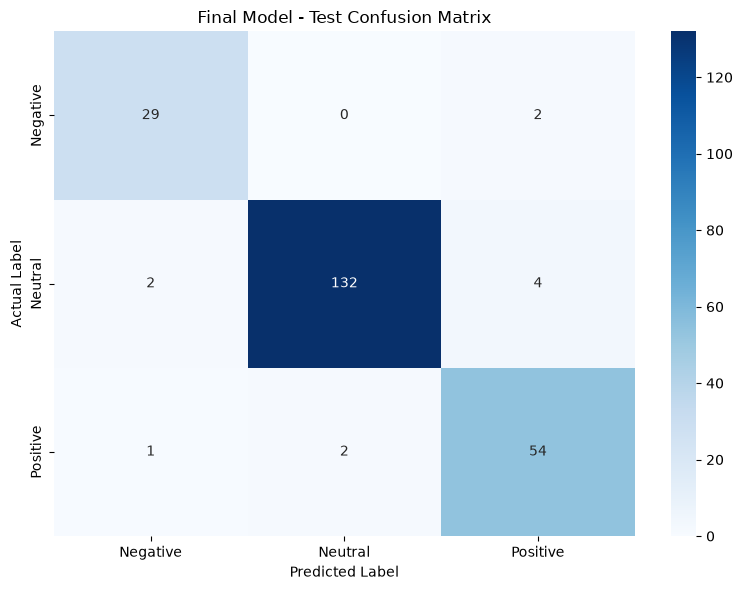

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

test_cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1, 2]
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    test_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Final Model - Test Confusion Matrix")
plt.tight_layout()

plt.savefig(
    "../figures/test_confusion_matrix.png",
    dpi=300
)

plt.show()

In [28]:
test_predictions_df = pd.DataFrame({

    "row_id": test_df.index.to_numpy(),

    "actual": y_true,

    "predicted": y_pred,

    "confidence": test_confidence.numpy(),

    "p_negative": test_probabilities[:, 0].numpy(),

    "p_neutral": test_probabilities[:, 1].numpy(),

    "p_positive": test_probabilities[:, 2].numpy(),

    "is_correct": test_correct_mask.numpy()
})

test_predictions_df.to_csv(
    "../reports/test_predictions.csv",
    index=False
)

test_predictions_df.head()

,row_id,actual,predicted,confidence,p_negative,p_neutral,p_positive,is_correct
0,1985,1,1,0.991657,0.003453,0.991657,0.004890,True
1,1818,1,1,0.994119,0.002019,0.994119,0.003862,True
2,802,2,2,0.974808,0.014359,0.010833,0.974808,True
3,1274,1,1,0.991606,0.002276,0.991606,0.006118,True
4,1487,1,1,0.994001,0.002346,0.994001,0.003653,True


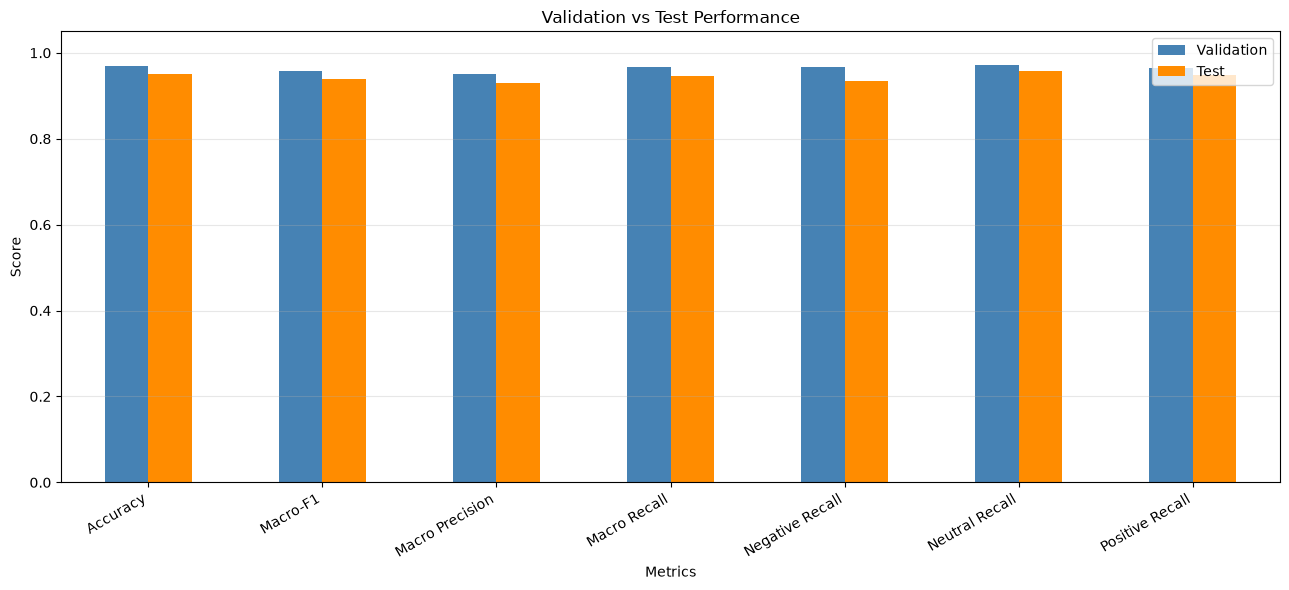

In [29]:
plot_df = metrics_df[metrics_df["Metric"] != "ECE"]

plot_df.set_index("Metric")[["Validation", "Test"]].plot(
    kind="bar",
    figsize=(13, 6),
    color=["steelblue", "darkorange"]
)

plt.title("Validation vs Test Performance")
plt.ylabel("Score")
plt.xlabel("Metrics")
plt.ylim(0, 1.05)
plt.xticks(rotation=30, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "../figures/validation_test_comparison.png",
    dpi=300
)

plt.show()

In [31]:
rng = np.random.default_rng(42)

n_bootstrap = 1000

bootstrap_scores = []

for _ in range(n_bootstrap):

    indices = rng.choice(
        len(y_true),
        size=len(y_true),
        replace=True
    )

    bootstrap_true = y_true[indices]

    bootstrap_pred = y_pred[indices]

    score = f1_score(
        bootstrap_true,
        bootstrap_pred,
        labels=[0, 1, 2],
        average="macro",
        zero_division=0
    )

    bootstrap_scores.append(score)

bootstrap_scores = np.array(bootstrap_scores)


ci_lower = np.percentile(bootstrap_scores, 2.5)

ci_upper = np.percentile(bootstrap_scores, 97.5)

print(f"Test Macro-F1: {test_macro_f1:.6f}")

print(f"Bootstrap Mean: {bootstrap_scores.mean():.6f}")

print(f"95% Confidence Interval: [{ci_lower:.6f}, {ci_upper:.6f}]")

Test Macro-F1: 0.938100
Bootstrap Mean: 0.937704
95% Confidence Interval: [0.897937, 0.973983]


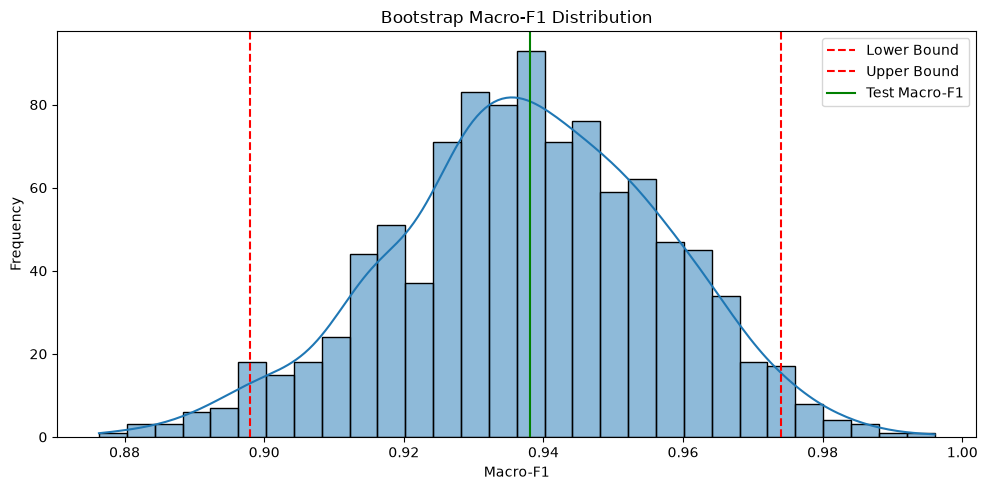

In [32]:
plt.figure(figsize=(10, 5))

sns.histplot(
    bootstrap_scores,
    bins=30,
    kde=True
)

plt.axvline(
    ci_lower,
    color="red",
    linestyle="--",
    label="Lower Bound"
)

plt.axvline(
    ci_upper,
    color="red",
    linestyle="--",
    label="Upper Bound"
)

plt.axvline(
    test_macro_f1,
    color="green",
    label="Test Macro-F1"
)

plt.xlabel("Macro-F1")
plt.ylabel("Frequency")
plt.title("Bootstrap Macro-F1 Distribution")
plt.legend()
plt.tight_layout()

plt.savefig(
    "../figures/bootstrap_confidence_interval.png",
    dpi=300
)

plt.show()

In [33]:
bootstrap_df = pd.DataFrame({

    "Test Macro-F1": [test_macro_f1],

    "Bootstrap Samples": [n_bootstrap],

    "Bootstrap Mean": [bootstrap_scores.mean()],

    "CI Lower": [ci_lower],

    "CI Upper": [ci_upper]

})

bootstrap_df.to_csv(
    "../reports/bootstrap_results.csv",
    index=False
)

bootstrap_df

,Test Macro-F1,Bootstrap Samples,Bootstrap Mean,CI Lower,CI Upper
0,0.9381,1000,0.937704,0.897937,0.973983


In [34]:
import time

batch_sizes = [1, 8, 16, 32]

n_repeats = 3
n_warmup = 5

benchmark_sentences = val_df["sentence"].tolist()

assert len(benchmark_sentences) == 226

final_model.to(device)
final_model.eval()

if model is not final_model:
    model.to("cpu")

if device.type == "cuda":
    torch.cuda.empty_cache()

print("Device:", device)
print("Samples:", len(benchmark_sentences))

Device: cuda
Samples: 226


In [35]:
def synchronize_device():
    if device.type == "cuda":
        torch.cuda.synchronize(device)

In [36]:
def inference_batch(sentences):

    inputs = final_tokenizer(
        sentences,
        padding=True,
        truncation=True,
        max_length=256,
        return_tensors="pt"
    ).to(device)

    with torch.inference_mode():

        logits = final_model(**inputs).logits

        probabilities = torch.softmax(logits, dim=1)

        confidence, predictions = probabilities.max(dim=1)

    return predictions.cpu(), confidence.cpu()

In [37]:
def benchmark_inference(batch_size, n_repeats=3, n_warmup=5):

    batch_latencies = []
    total_times = []
    peak_memories = []

    for repeat in range(n_repeats):

        for _ in range(n_warmup):
            inference_batch(benchmark_sentences[:batch_size])

        synchronize_device()

        if device.type == "cuda":
            torch.cuda.reset_peak_memory_stats(device)

        start_total = time.perf_counter()

        for i in range(0, len(benchmark_sentences), batch_size):

            batch = benchmark_sentences[i:i + batch_size]

            synchronize_device()

            start = time.perf_counter()

            inference_batch(batch)

            synchronize_device()

            end = time.perf_counter()

            batch_latency = (end - start) * 1000

            batch_latencies.append(batch_latency)

        end_total = time.perf_counter()

        total_time = end_total - start_total

        total_times.append(total_time)

        if device.type == "cuda":

            peak_memory = torch.cuda.max_memory_allocated(device) / 1e6

            peak_memories.append(peak_memory)

    throughput = (
        len(benchmark_sentences) * n_repeats
    ) / sum(total_times)

    return {
        "batch_size": batch_size,
        "mean_batch_latency_ms": np.mean(batch_latencies),
        "p95_batch_latency_ms": np.percentile(batch_latencies, 95),
        "throughput_samples_sec": throughput,
        "mean_total_time_sec": np.mean(total_times),
        "peak_gpu_memory_mb": max(peak_memories) if peak_memories else np.nan
    }

In [39]:
benchmark_results = []

for batch_size in batch_sizes:

    result = benchmark_inference(
        batch_size=batch_size,
        n_repeats=n_repeats,
        n_warmup=n_warmup
    )

    benchmark_results.append(result)

    print(f"Batch Size {batch_size}: Completed")

benchmark_df = pd.DataFrame(benchmark_results)

benchmark_df.round(4)

Batch Size 1: Completed
Batch Size 8: Completed
Batch Size 16: Completed
Batch Size 32: Completed


,batch_size,mean_batch_latency_ms,p95_batch_latency_ms,throughput_samples_sec,mean_total_time_sec,peak_gpu_memory_mb
0,1,1.6581,1.9150,600.9045,0.3761,279.7471
1,8,6.5685,9.1267,1184.8242,0.1907,297.2237
2,16,11.5064,14.3045,1308.6036,0.1727,314.0326
3,32,21.2115,26.7227,1331.3003,0.1698,352.1905


In [40]:
benchmark_df.to_csv(
    "../reports/inference_benchmark.csv",
    index=False
)

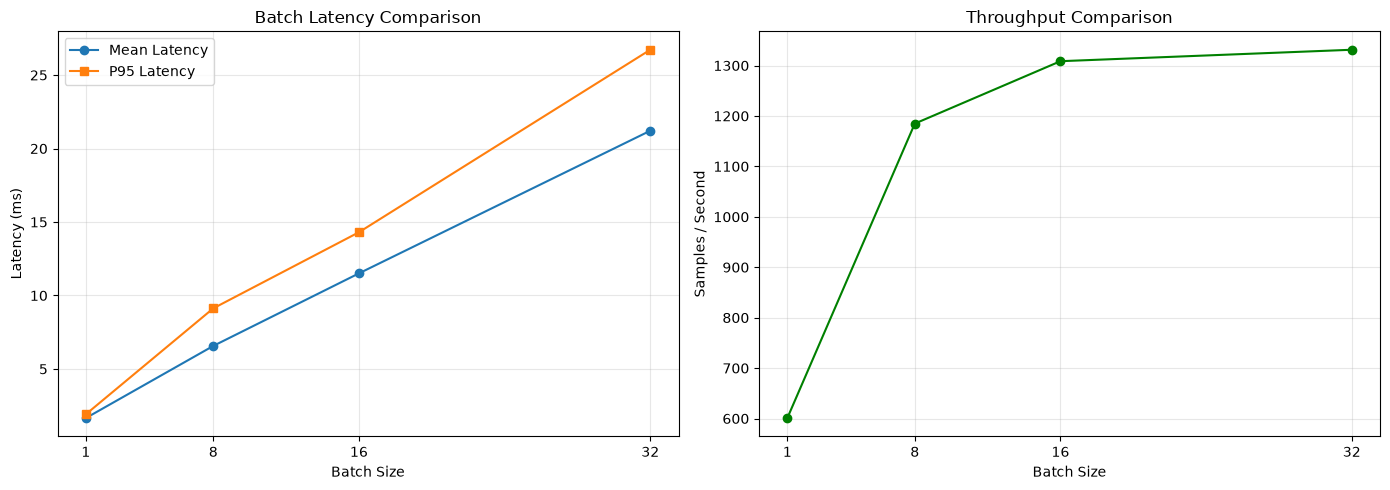

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    benchmark_df["batch_size"],
    benchmark_df["mean_batch_latency_ms"],
    marker="o",
    label="Mean Latency"
)

axes[0].plot(
    benchmark_df["batch_size"],
    benchmark_df["p95_batch_latency_ms"],
    marker="s",
    label="P95 Latency"
)

axes[0].set_title("Batch Latency Comparison")
axes[0].set_xlabel("Batch Size")
axes[0].set_ylabel("Latency (ms)")
axes[0].set_xticks(batch_sizes)
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    benchmark_df["batch_size"],
    benchmark_df["throughput_samples_sec"],
    marker="o",
    color="green"
)

axes[1].set_title("Throughput Comparison")
axes[1].set_xlabel("Batch Size")
axes[1].set_ylabel("Samples / Second")
axes[1].set_xticks(batch_sizes)
axes[1].grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "../figures/latency_throughput_comparison.png",
    dpi=300
)

plt.show()

In [42]:
best_throughput = benchmark_df.loc[
    benchmark_df["throughput_samples_sec"].idxmax()
]

best_latency = benchmark_df.loc[
    benchmark_df["mean_batch_latency_ms"].idxmin()
]

print("Best Throughput Batch Size:", int(best_throughput["batch_size"]))

print("Best Throughput:", best_throughput["throughput_samples_sec"])

print("Best Latency Batch Size:", int(best_latency["batch_size"]))

print("Best Latency:", best_latency["mean_batch_latency_ms"])

Best Throughput Batch Size: 32
Best Throughput: 1331.3002924824818
Best Latency Batch Size: 1
Best Latency: 1.6580720811359289


In [43]:
total_samples = 1_000_000

benchmark_df["million_samples_seconds"] = (
    total_samples / benchmark_df["throughput_samples_sec"]
)

benchmark_df["million_samples_minutes"] = (
    benchmark_df["million_samples_seconds"] / 60
)

benchmark_df["million_samples_hours"] = (
    benchmark_df["million_samples_seconds"] / 3600
)

benchmark_df[[
    "batch_size",
    "throughput_samples_sec",
    "million_samples_minutes",
    "million_samples_hours"
]].round(4)

,batch_size,throughput_samples_sec,million_samples_minutes,million_samples_hours
0,1,600.9045,27.7360,0.4623
1,8,1184.8242,14.0668,0.2344
2,16,1308.6036,12.7362,0.2123
3,32,1331.3003,12.5191,0.2087


In [44]:
training_results = pd.read_csv(
    "../reports/length_experiment_results.csv"
)

training_results

,max_length,train_loss,val_loss,val_accuracy,val_macro_f1,val_negative_recall,val_neutral_recall,val_positive_recall,global_step,best_checkpoint
0,128,0.300558,0.115270,0.964602,0.949958,0.933333,0.978417,0.947368,339,../models/length_experiment_128/checkpoint-339
1,256,0.297725,0.117045,0.969027,0.958797,0.966667,0.971223,0.964912,339,../models/length_experiment_256/checkpoint-339


In [45]:
resource_results = pd.read_csv(
    "../reports/sequence_length_comparison.csv"
)

resource_results

,max_length,train_loss,val_loss,val_accuracy,val_macro_f1,val_macro_precision,val_macro_recall,val_negative_recall,val_neutral_recall,val_positive_recall,training_time_s,peak_gpu_memory_mb,best_epoch,global_step,best_checkpoint
0,128,0.300558,0.115270,0.964602,0.949958,0.947096,0.953040,0.933333,0.978417,0.947368,18.043863,1514.970624,3.0,339,../models/length_resource_experiment_128/check...
1,256,0.297725,0.117045,0.969027,0.958797,0.950717,0.967601,0.966667,0.971223,0.964912,18.087495,1633.617408,3.0,339,../models/length_resource_experiment_256/check...


In [46]:
benchmark_df.to_csv(
    "../reports/inference_benchmark.csv",
    index=False
)

In [49]:
test_token_lengths = [
    len(final_tokenizer(sentence, truncation=False)["input_ids"])
    for sentence in test_sentences
]

test_predictions_df["token_length"] = test_token_lengths

test_predictions_df["sentence"] = test_sentences

test_predictions_df["actual_label"] = test_predictions_df["actual"].map(
    final_model.config.id2label
)

test_predictions_df["predicted_label"] = test_predictions_df["predicted"].map(
    final_model.config.id2label
)

test_error_df = test_predictions_df[
    ~test_predictions_df["is_correct"]
].copy()

test_error_df = test_error_df.sort_values(
    by="confidence",
    ascending=False
)

print("Total Test Errors:", len(test_error_df))

pd.set_option("display.max_colwidth", None)

test_error_df[[
    "row_id",
    "sentence",
    "actual_label",
    "predicted_label",
    "confidence",
    "token_length"
]]

Total Test Errors: 11


,row_id,sentence,actual_label,predicted_label,confidence,token_length
76,2051,"These financing arrangements will enable the company to ensure , in line with its treasury policy , that it has sufficient financial instruments at its disposal for its potential capital requirements .",Positive,Neutral,0.991125,34
222,371,"Finnish power supply solutions and systems provider Efore Oyj said its net loss widened to 3.2 mln euro $ 4.2 mln for the first quarter of fiscal 2006-2007 ending October 31 , 2007 from 900,000 euro $ 1.2 mln for the same period of fiscal 2005-06 .",Negative,Positive,0.973732,68
109,809,Viking Line manages well with its current ferries .,Positive,Neutral,0.965592,11
164,480,These moderate but significant changes resulted in a significant 24-32 % reduction in the estimated CVD risk .,Positive,Negative,0.940642,23
39,1579,`` These developments partly reflect the government 's higher activity in the field of dividend policy . '',Neutral,Positive,0.930700,24
190,538,Amanda said that it had already made a USD5 .0 m investment commitment in Russia Partners II fund in July 2005 .,Neutral,Positive,0.929065,26
194,1921,"The company reported a profit of 800,000 euro ($ 1.2 mln)on the sale of its Varesvuo Partners sub-group and a loss of 400,000 euro $ 623,000 caused by the sale of its program production subsidiary Oy Filmiteollisuus Fine Ab .",Neutral,Negative,0.899655,66
202,1163,Another firm Air Liquide was exempted because it left the market in 1998 .,Neutral,Negative,0.863067,18
100,1648,"In April-June 2008 , Scanfil 's net sales totalled EUR 58.7 mn and operating profit EUR 6.6 mn .",Neutral,Positive,0.658158,33
209,1642,In 2008 Stockmann earned 3.398 million lats in profit on 48.012 million lats in turnover .,Neutral,Positive,0.628374,27


In [51]:
test_error_df["neutral_to_positive"] = (
    (test_error_df["actual"] == 1) &
    (test_error_df["predicted"] == 2)
)

test_error_df["negative_to_positive"] = (
    (test_error_df["actual"] == 0) &
    (test_error_df["predicted"] == 2)
)

test_error_df["high_confidence_error"] = (
    test_error_df["confidence"] >= 0.90
)

test_error_df["possible_truncation"] = (
    test_error_df["token_length"] > 256
)

error_comparison_df = pd.DataFrame({

    "Error Category": [
        "Cost Reduction Misinterpretation",
        "Neutral to Positive",
        "Negative to Positive",
        "High Confidence Errors",
        "Possible Truncation Errors"
    ],

    "Validation": [
        2,
        4,
        1,
        4,
        0
    ],

    "Test": [
        np.nan,
        test_error_df["neutral_to_positive"].sum(),
        test_error_df["negative_to_positive"].sum(),
        test_error_df["high_confidence_error"].sum(),
        test_error_df["possible_truncation"].sum()
    ]
})

error_comparison_df

,Error Category,Validation,Test
0,Cost Reduction Misinterpretation,2,NaN
1,Neutral to Positive,4,4.0
2,Negative to Positive,1,2.0
3,High Confidence Errors,4,6.0
4,Possible Truncation Errors,0,0.0


In [52]:
robustness_df = pd.DataFrame({

    "category": [
        "Cost Reduction",
        "Cost Increase",
        "Profit Reduction",
        "Profit Increase",
        "Negation",
        "Loss Reduction",
        "Debt Increase",
        "Future Growth Target",
        "Actual Growth",
        "Mixed Sentiment"
    ],

    "sentence": [
        "Operating costs decreased by 20%.",
        "Operating costs increased by 20%.",
        "Operating profit decreased by 20%.",
        "Operating profit increased by 20%.",
        "Operating profit did not increase and remained unchanged.",
        "The company's net loss decreased by 30%.",
        "The company's debt increased by 20% while cash reserves remained unchanged.",
        "The company aims to increase revenue by 10% next year.",
        "The company increased revenue by 10% this year.",
        "Revenue increased by 10%, but operating profit decreased by 10%."
    ],

    "expected": [
        2,
        0,
        0,
        2,
        1,
        2,
        0,
        1,
        2,
        1
    ]
})

robustness_df

,category,sentence,expected
0,Cost Reduction,Operating costs decreased by 20%.,2
1,Cost Increase,Operating costs increased by 20%.,0
2,Profit Reduction,Operating profit decreased by 20%.,0
3,Profit Increase,Operating profit increased by 20%.,2
4,Negation,Operating profit did not increase and remained unchanged.,1
5,Loss Reduction,The company's net loss decreased by 30%.,2
6,Debt Increase,The company's debt increased by 20% while cash reserves remained unchanged.,0
7,Future Growth Target,The company aims to increase revenue by 10% next year.,1
8,Actual Growth,The company increased revenue by 10% this year.,2
9,Mixed Sentiment,"Revenue increased by 10%, but operating profit decreased by 10%.",1


In [54]:
robustness_logits, robustness_probs, robustness_preds = get_predictions(
    final_model,
    final_tokenizer,
    robustness_df["sentence"].tolist()
)

robustness_df["predicted"] = robustness_preds.numpy()

robustness_df["confidence"] = robustness_probs.max(dim=1).values.numpy()

robustness_df["p_negative"] = robustness_probs[:, 0].numpy()

robustness_df["p_neutral"] = robustness_probs[:, 1].numpy()

robustness_df["p_positive"] = robustness_probs[:, 2].numpy()

robustness_df["is_correct"] = (
    robustness_df["expected"] == robustness_df["predicted"]
)

robustness_df["expected_label"] = robustness_df["expected"].map(
    final_model.config.id2label
)

robustness_df["predicted_label"] = robustness_df["predicted"].map(
    final_model.config.id2label
)

robustness_df[[
    "category",
    "sentence",
    "expected_label",
    "predicted_label",
    "confidence",
    "is_correct"
]]

,category,sentence,expected_label,predicted_label,confidence,is_correct
0,Cost Reduction,Operating costs decreased by 20%.,Positive,Negative,0.969307,False
1,Cost Increase,Operating costs increased by 20%.,Negative,Positive,0.974218,False
2,Profit Reduction,Operating profit decreased by 20%.,Negative,Negative,0.970819,True
3,Profit Increase,Operating profit increased by 20%.,Positive,Positive,0.976044,True
4,Negation,Operating profit did not increase and remained unchanged.,Neutral,Positive,0.807488,False
5,Loss Reduction,The company's net loss decreased by 30%.,Positive,Negative,0.970356,False
6,Debt Increase,The company's debt increased by 20% while cash reserves remained unchanged.,Negative,Positive,0.973829,False
7,Future Growth Target,The company aims to increase revenue by 10% next year.,Neutral,Positive,0.977778,False
8,Actual Growth,The company increased revenue by 10% this year.,Positive,Positive,0.978089,True
9,Mixed Sentiment,"Revenue increased by 10%, but operating profit decreased by 10%.",Neutral,Negative,0.951991,False


In [55]:
robustness_accuracy = robustness_df["is_correct"].mean()

print(f"Robustness Accuracy: {robustness_accuracy:.2%}")

print("Correct:", robustness_df["is_correct"].sum())

print("Incorrect:", (~robustness_df["is_correct"]).sum())

Robustness Accuracy: 30.00%
Correct: 3
Incorrect: 7


In [56]:
robustness_df[
    ~robustness_df["is_correct"]
][[
    "category",
    "sentence",
    "expected_label",
    "predicted_label",
    "confidence"
]]

,category,sentence,expected_label,predicted_label,confidence
0,Cost Reduction,Operating costs decreased by 20%.,Positive,Negative,0.969307
1,Cost Increase,Operating costs increased by 20%.,Negative,Positive,0.974218
4,Negation,Operating profit did not increase and remained unchanged.,Neutral,Positive,0.807488
5,Loss Reduction,The company's net loss decreased by 30%.,Positive,Negative,0.970356
6,Debt Increase,The company's debt increased by 20% while cash reserves remained unchanged.,Negative,Positive,0.973829
7,Future Growth Target,The company aims to increase revenue by 10% next year.,Neutral,Positive,0.977778
9,Mixed Sentiment,"Revenue increased by 10%, but operating profit decreased by 10%.",Neutral,Negative,0.951991


In [57]:
robustness_df.to_csv(
    "../reports/robustness_analysis.csv",
    index=False
)

In [58]:
test_results = []

def run_test(name, test_function):

    try:
        test_function()

        test_results.append({
            "test": name,
            "status": "PASSED"
        })

        print(f"{name}: PASSED")

    except Exception as e:

        test_results.append({
            "test": name,
            "status": "FAILED",
            "error": str(e)
        })

        print(f"{name}: FAILED - {e}")

def test_model_reload():

    global reloaded_model, reloaded_tokenizer

    reloaded_model = AutoModelForSequenceClassification.from_pretrained(
        final_path
    ).to(device)

    reloaded_tokenizer = AutoTokenizer.from_pretrained(final_path)

    reloaded_model.eval()

    assert reloaded_model.config.num_labels == 3

def test_tokenizer_consistency():

    texts = sample_df["sentence"].tolist()

    original = tokenizer(
        texts,
        padding=True,
        truncation=True,
        max_length=256,
        return_tensors="pt"
    )

    reloaded = reloaded_tokenizer(
        texts,
        padding=True,
        truncation=True,
        max_length=256,
        return_tensors="pt"
    )

    assert torch.equal(
        original["input_ids"],
        reloaded["input_ids"]
    )

    assert torch.equal(
        original["attention_mask"],
        reloaded["attention_mask"]
    )

def test_prediction_consistency():

    _, _, preds = get_predictions(
        reloaded_model,
        reloaded_tokenizer,
        sample_df["sentence"].tolist()
    )

    assert torch.equal(original_preds, preds)

def test_logits_consistency():

    logits, _, _ = get_predictions(
        reloaded_model,
        reloaded_tokenizer,
        sample_df["sentence"].tolist()
    )

    assert torch.allclose(
        original_logits,
        logits,
        atol=1e-6,
        rtol=1e-5
    )

def test_integrity():

    assert len(test_df) == 226

    assert test_df["sentence"].nunique() == 226

    assert test_df[["sentence", "label"]].notna().all().all()

    assert set(test_df["label"]) == {0, 1, 2}

    assert test_logits.shape == (226, 3)

    assert np.array_equal(
        test_labels.numpy(),
        test_df["label"].to_numpy()
    )

def test_data_leakage():

    train_sentences_set = set(train_df["sentence"])

    val_sentences_set = set(val_df["sentence"])

    test_sentences_set = set(test_df["sentence"])

    assert train_sentences_set.isdisjoint(val_sentences_set)

    assert train_sentences_set.isdisjoint(test_sentences_set)

    assert val_sentences_set.isdisjoint(test_sentences_set)

def test_probability_validity():

    assert test_probabilities.shape == (226, 3)

    assert torch.isfinite(test_probabilities).all()

    assert (test_probabilities >= 0).all()

    assert (test_probabilities <= 1).all()

    assert torch.allclose(
        test_probabilities.sum(dim=1),
        torch.ones_like(test_confidence),
        atol=1e-6
    )

def test_metric_validity():

    values = metrics_df[["Validation", "Test"]].to_numpy(
        dtype=float
    )

    assert np.isfinite(values).all()

    assert (values >= 0).all()

    assert (values <= 1).all()

def test_latency_validity():

    columns = [
        "mean_batch_latency_ms",
        "p95_batch_latency_ms",
        "throughput_samples_sec"
    ]

    values = benchmark_df[columns].to_numpy()

    assert set(benchmark_df["batch_size"]) == {1, 8, 16, 32}

    assert np.isfinite(values).all()

    assert (values > 0).all()

    if device.type == "cuda":

        memory = benchmark_df["peak_gpu_memory_mb"].to_numpy()

        assert np.isfinite(memory).all()

        assert (memory > 0).all()

def test_batch_consistency():

    reference_predictions = None

    texts = val_df["sentence"].tolist()

    for bs in [1, 8, 16, 32]:

        batch_predictions = []

        for i in range(0, len(texts), bs):

            preds, _ = inference_batch(
                texts[i:i + bs]
            )

            batch_predictions.append(preds)

        predictions = torch.cat(batch_predictions)

        if reference_predictions is None:

            reference_predictions = predictions

        else:

            assert torch.equal(
                reference_predictions,
                predictions
            ), f"Prediction mismatch at batch size {bs}"

def test_error_consistency():

    actual_errors = (
        test_predictions != test_labels
    ).sum().item()

    matrix_errors = test_cm.sum() - np.trace(test_cm)

    assert actual_errors == matrix_errors

    assert actual_errors == len(test_error_df)

    assert test_cm.sum() == 226

def test_calibration_validity():

    assert np.isfinite(test_ece)

    assert 0 <= test_ece <= 1

    assert test_bin_results["count"].sum() == 226

    toy_confidence = torch.tensor([
        0.25, 0.35, 0.85, 0.95
    ])

    toy_correct = torch.tensor([
        False, True, True, True
    ])

    toy_ece, _ = calculate_ece(
        toy_confidence,
        toy_correct,
        n_bins=5
    )

    assert np.isclose(toy_ece, 0.15, atol=1e-6)

run_test("Test 1 — Model Reload", test_model_reload)

run_test("Test 2 — Tokenizer Consistency", test_tokenizer_consistency)

run_test("Test 3 — Prediction Consistency", test_prediction_consistency)

run_test("Test 4 — Logits Consistency", test_logits_consistency)

run_test("Test 5 — Test Integrity", test_integrity)

run_test("Test 6 — Data Leakage", test_data_leakage)

run_test("Test 7 — Probability Validity", test_probability_validity)

run_test("Test 8 — Metric Validity", test_metric_validity)

run_test("Test 9 — Latency Validity", test_latency_validity)

run_test("Test 10 — Batch Consistency", test_batch_consistency)

run_test("Test 11 — Error Consistency", test_error_consistency)

run_test("Test 12 — Calibration Validity", test_calibration_validity)

tests_df = pd.DataFrame(test_results)

print()

print("Total Tests:", len(tests_df))

print("Passed:", (tests_df["status"] == "PASSED").sum())

print("Failed:", (tests_df["status"] == "FAILED").sum())

tests_df.to_csv(
    "../reports/final_test_results.csv",
    index=False
)

display(tests_df)

Loading weights: 100%|██████████| 104/104 [00:00<00:00, 5688.45it/s]


Test 1 — Model Reload: PASSED
Test 2 — Tokenizer Consistency: PASSED
Test 3 — Prediction Consistency: PASSED
Test 4 — Logits Consistency: PASSED
Test 5 — Test Integrity: PASSED
Test 6 — Data Leakage: PASSED
Test 7 — Probability Validity: PASSED
Test 8 — Metric Validity: PASSED
Test 9 — Latency Validity: PASSED
Test 10 — Batch Consistency: PASSED
Test 11 — Error Consistency: PASSED
Test 12 — Calibration Validity: PASSED

Total Tests: 12
Passed: 12
Failed: 0


,test,status
0,Test 1 — Model Reload,PASSED
1,Test 2 — Tokenizer Consistency,PASSED
2,Test 3 — Prediction Consistency,PASSED
3,Test 4 — Logits Consistency,PASSED
4,Test 5 — Test Integrity,PASSED
5,Test 6 — Data Leakage,PASSED
6,Test 7 — Probability Validity,PASSED
7,Test 8 — Metric Validity,PASSED
8,Test 9 — Latency Validity,PASSED
9,Test 10 — Batch Consistency,PASSED
